In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())
print(df.head())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [3]:
y = df["resolution_hours"]
X = df[["complexity_score", "team_experience_years", "reopened"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

print(X_train.shape, X_test.shape)

def metrics(y_true, pred):
    return (mean_absolute_error(y_true, pred),
            mean_squared_error(y_true, pred) ** 0.5,
            r2_score(y_true, pred))

(192, 3) (48, 3)


## Task 2: Features
- Excluded ticket_id: just an identifier.
- Excluded lines_changed: only known after the fix (leakage).
- Used complexity_score, team_experience_years, reopened.
- reopened is a caveat: only known after resolution.

In [4]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
print(metrics(y_test, dummy.predict(X_test)))

(9.113951822916667, 10.597684800766308, -0.021016765260001957)


In [5]:
lin = LinearRegression().fit(X_train, y_train)
pred_lin = lin.predict(X_test)
print(metrics(y_test, pred_lin))
print(dict(zip(X.columns, lin.coef_.round(3))), lin.intercept_)

(2.5905403654464028, 3.219152904435669, 0.9057906326651207)
{'complexity_score': np.float64(2.964), 'team_experience_years': np.float64(-0.342), 'reopened': np.float64(4.184)} 4.070641372726964


In [6]:
def poly_pipe(d):
    return make_pipeline(PolynomialFeatures(d, include_bias=False),
                         StandardScaler(), LinearRegression())

for name, m in [("linear", LinearRegression()), ("deg2", poly_pipe(2)), ("deg3", poly_pipe(3))]:
    cv_rmse = -cross_val_score(m, X_train, y_train, cv=cv,
                               scoring="neg_root_mean_squared_error")
    m.fit(X_train, y_train)
    train_rmse = mean_squared_error(y_train, m.predict(X_train)) ** 0.5
    print(name, "CV", cv_rmse.mean().round(3), "+-", cv_rmse.std().round(3),
          "train", round(train_rmse, 3))

linear CV 3.521 +- 0.267 train 3.463
deg2 CV 3.512 +- 0.29 train 3.336
deg3 CV 3.622 +- 0.232 train 3.274


In [7]:
for d in (2, 3):
    m = poly_pipe(d).fit(X_train, y_train)
    print(d, metrics(y_test, m.predict(X_test)))

2 (2.781772314755969, 3.552810542895765, 0.8852493975607523)


3 (2.823330302232885, 3.624918110442918, 0.8805441903044359)


In [8]:
def tune(est, grid):
    pipe = Pipeline([("scale", StandardScaler()), ("model", est)])
    return GridSearchCV(pipe, {"model__alpha": grid}, cv=cv,
                        scoring="neg_root_mean_squared_error").fit(X_train, y_train)

gs_r = tune(Ridge(), np.logspace(-3, 3, 31))
gs_l = tune(Lasso(max_iter=100_000), np.logspace(-3, 1, 31))

print("Ridge alpha", gs_r.best_params_, metrics(y_test, gs_r.predict(X_test)))
print("Lasso alpha", gs_l.best_params_, metrics(y_test, gs_l.predict(X_test)))

Ridge alpha {'model__alpha': np.float64(0.001)} (2.590545226414199, 3.2191556203681224, 0.9057904737000801)
Lasso alpha {'model__alpha': np.float64(0.001)} (2.590627595310235, 3.219184766639424, 0.9057887677441295)


In [9]:
p3 = Pipeline([("poly", PolynomialFeatures(3, include_bias=False)),
               ("scale", StandardScaler()), ("model", Ridge())])
gs = GridSearchCV(p3, {"model__alpha": np.logspace(-3, 3, 31)}, cv=cv,
                  scoring="neg_root_mean_squared_error").fit(X_train, y_train)

print("Poly3 OLS   max |coef|:", np.abs(poly_pipe(3).fit(X_train, y_train)[-1].coef_).max().round(2))
print("Poly3 Ridge max |coef|:", np.abs(gs.best_estimator_[-1].coef_).max().round(2))
print("Poly3 Ridge alpha:", gs.best_params_, metrics(y_test, gs.predict(X_test)))

Poly3 OLS   max |coef|: 14.27
Poly3 Ridge max |coef|: 5.29
Poly3 Ridge alpha: {'model__alpha': np.float64(2.5118864315095824)} (2.7836338087440677, 3.5066184223295167, 0.8882138763616384)


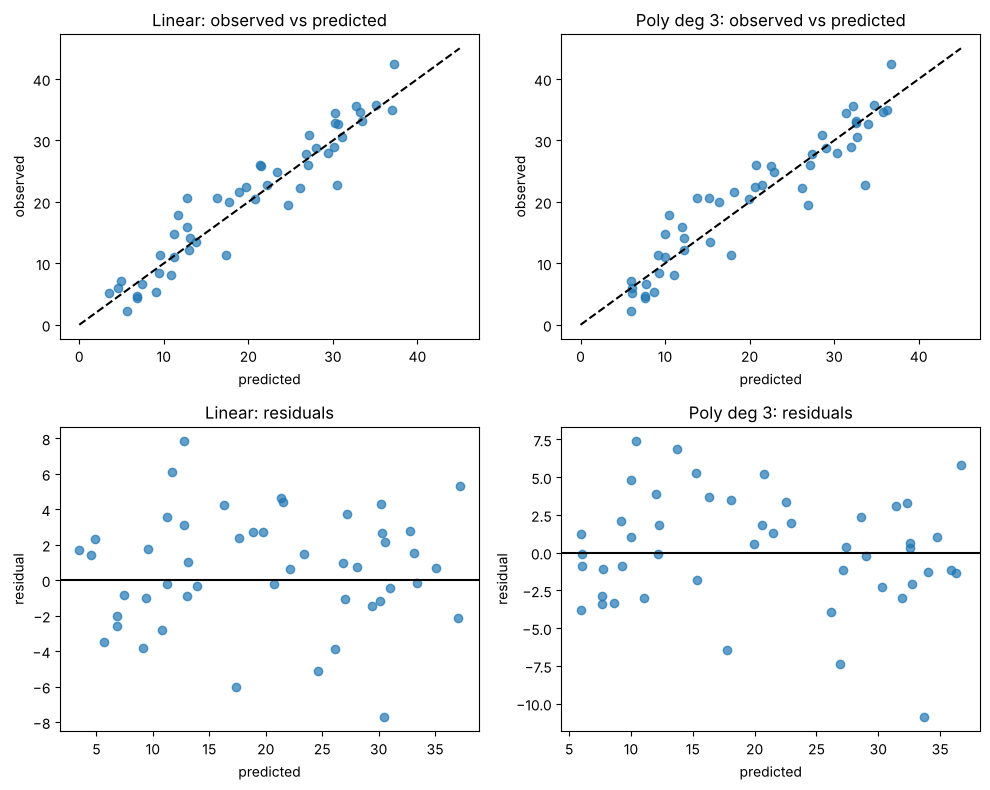

In [10]:
pred_p3 = poly_pipe(3).fit(X_train, y_train).predict(X_test)
models = {"Linear": pred_lin, "Poly deg 3": pred_p3}

fig, ax = plt.subplots(2, 2, figsize=(10, 8))
for j, (name, p) in enumerate(models.items()):
    ax[0, j].scatter(p, y_test, alpha=.7)
    ax[0, j].plot([0, 45], [0, 45], "k--")
    ax[0, j].set(title=f"{name}: observed vs predicted", xlabel="predicted", ylabel="observed")

    ax[1, j].scatter(p, y_test - p, alpha=.7)
    ax[1, j].axhline(0, c="k")
    ax[1, j].set(title=f"{name}: residuals", xlabel="predicted", ylabel="residual")
plt.tight_layout()
plt.show()

## Task 8: Plot findings
- Both models follow the diagonal well.
- Linear residuals are random around 0 (about ±8 h): no curvature, no extreme outliers.
- Poly deg 3 has larger misses (down to -11 h) and over-predicts small tickets, a sign of overfitting.
- Spread is roughly constant, with no strong funnel shape.

## Task 9: Recommendation
I choose plain Linear Regression.
- Lowest test error: MAE 2.59, RMSE 3.22, R² 0.906 (baseline MAE 9.11).
- Polynomial degrees 2 and 3 did not improve CV RMSE (3.51 and 3.62 vs 3.52), and degree 3 overfits.
- Ridge and Lasso chose alpha = 0.001 and gave the same result, so regularization is not needed.
- The residuals look random.

Before deployment: get real data, use a time-based split, and check whether `reopened` is known at prediction time.

## Analysis questions

**10. Why use a mean baseline?**

It is the minimum any model must beat. Linear cut MAE from 9.11 to 2.59.

**11. Lowest MAE and RMSE?**

Linear: MAE 2.59, RMSE 3.22. RMSE punishes big errors more, so the two can differ.

**12. Did polynomial features help?**

No. CV RMSE: 3.52 (linear), 3.51 (deg 2), 3.62 (deg 3). Degree 3 overfits.

**13. Effect of regularization?**

On linear features, Ridge and Lasso chose alpha = 0.001 and scored the same as linear, so they had no effect. On degree-3 features, Ridge shrank the largest coefficient from about 14.3 to 5.3 and improved test RMSE from 3.63 to 3.51, but it still did not beat plain linear (3.22).

**14. Why scale for Ridge/Lasso?**

So the penalty treats all features fairly, whatever their units.

**15. Leakage?**

`lines_changed` is only known after the fix, so I removed it. `reopened` is a caveat.

**16. Random split OK for multi-year data?**

No. Use a time-based split or group by team.

**17. Tests before deployment?**

Time-based validation, real data, subgroup checks, and monitoring after launch.